# Predicting Customer Repeat Purchase Behaviour Using Machine Learning
## 1. Data import and exploration
### 1.1. Introduction and objective
#### Everything & Then Some, Ltd. is a diversified wholesale company whose customers exhibit different purchasing behaviours.
#### The objective of this project is to develop a machine learning model that predicts whether a customer will make another purchase within 90 days after a given transaction.
#### The first phase focuses on understanding the available datasets, exploring the variables, assessing data quality, and identifying relevant patterns that may help predict repeat-purchase behaviour.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
train = pd.read_csv("data/train.csv", index_col="ID")
test = pd.read_csv("data/test.csv")
clientes = pd.read_csv("data/clientes.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

print("All files loaded successfully!")

All files loaded successfully!


In [40]:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.110000,510.900000,453.750000,104.360000,0.000000,0.000000,57.150000,153.099911,4.000000,1.000000,...,858.300000,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.800000,830.020000,795.770000,183.030000,0.000000,0.000000,34.250000,472.943134,32.000000,1.000000,...,"2,500.680000",189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.330000,12.000000,8.400000,1.930000,0.000000,0.000000,3.600000,6.097485,1.000000,1.000000,...,"7,899.800000",103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.830000,696.610000,696.610000,160.220000,0.000000,0.000000,0.000000,408.167275,9.000000,1.000000,...,270.330000,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,"1,616.100000","1,488.850000","1,313.900000",302.200000,0.000000,0.000000,174.950000,485.401864,33.000000,1.000000,...,"2,062.500000",122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [41]:
train.tail()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10007670,"3,023.340000","3,761.380000","2,458.000000",565.340000,0.000000,0.000000,"1,303.380000","1,099.190000",49.000000,1.000000,...,"5,548.200000",151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,-1.579719
10007671,"1,362.260000","1,723.100000","1,107.530000",254.730000,0.000000,34.250000,581.320000,197.514000,16.000000,1.000000,...,0.000000,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,-0.576883
10007672,"4,396.550000","3,574.430000","3,574.430000",822.120000,0.000000,0.000000,0.000000,"2,075.838024",78.000000,1.000000,...,"27,824.520000",755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,0.528377
10007673,452.070000,483.600000,367.540000,84.530000,0.000000,0.000000,116.060000,265.159468,7.000000,1.000000,...,"12,484.200000",703834,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,1.012809
10007674,951.710000,982.000000,773.750000,177.960000,0.000000,0.000000,208.250000,224.543079,30.000000,1.000000,...,"2,256.280000",438652,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 3,2019-11-23,-0.041337


In [42]:
train.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

In [43]:
# To keep 6 decimal places without scientific notation (e+)
pd.set_option('display.float_format','{:,.6f}'.format)

In [44]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,"6,469.000000",925.556262,"1,334.997733",0.930000,188.920000,476.740000,"1,087.670000","22,297.210000"
Total Bruto,"6,469.000000",886.152705,"1,327.641086",0.830000,175.740000,445.740000,"1,036.700000","21,578.280000"
Total Liquido,"6,469.000000",773.336384,"1,136.355723",0.760000,154.380000,389.910000,903.370000,"18,127.810000"
Total Imp_,"6,469.000000",152.219878,225.262375,0.000000,29.930000,79.740000,184.840000,"4,169.400000"
Total Portes,"6,469.000000",1.151427,5.844091,0.000000,0.000000,0.000000,0.000000,181.060000
Total Desc_ Global,"6,469.000000",0.349907,5.116564,0.000000,0.000000,0.000000,0.000000,218.490000
Total Desc_ Linha,"6,469.000000",112.466414,289.986307,0.000000,0.000000,13.130000,92.280000,"4,103.440000"
Custo,"6,469.000000",328.165040,519.507218,0.000000,49.050000,152.540000,396.061499,"7,427.400583"
N_ Detalhes,"6,469.000000",21.524501,27.713419,1.000000,4.000000,11.000000,29.000000,423.000000
invoice_count_current_purchase,"6,469.000000",1.066007,0.310807,1.000000,1.000000,1.000000,1.000000,5.000000


In [21]:
col_str = ["payment_type", "salesperson", "commercial_zone", 
           "transport_method", "warehouse", "document_series"]

In [25]:
for col in col_str:
    print(f"\nUnique values in {col}:")
    print(train[col].unique())


Unique values in payment_type:
<ArrowStringArray>
['Maybe Tomorrow Payment 10',  'Maybe Tomorrow Payment 7',
  'Maybe Tomorrow Payment 9', 'Maybe Tomorrow Payment 12',
                         nan,  'Maybe Tomorrow Payment 2',
  'Maybe Tomorrow Payment 8',  'Maybe Tomorrow Payment 3',
  'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 11']
Length: 10, dtype: str

Unique values in salesperson:
<ArrowStringArray>
['VLOOKUP Master 9', 'VLOOKUP Master 1', 'VLOOKUP Master 4',
                nan, 'VLOOKUP Master 2', 'VLOOKUP Master 7',
 'VLOOKUP Master 6', 'VLOOKUP Master 3', 'VLOOKUP Master 5',
 'VLOOKUP Master 8']
Length: 10, dtype: str

Unique values in commercial_zone:
<ArrowStringArray>
['Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 2',
 'Decorative Dashboard Zone 3',                           nan,
 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
Length: 6, dtype: str

Unique values in transport_method:
<ArrowStringArray>
['Maybe Tomorrow Delivery 61', 'Ma

1.2 Qualidade dos dados e inconsistências

In [45]:
train.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

In [46]:
# 5924 linhas onde o cliente já tinha aparecido
print(train['customer_id'].duplicated().sum())

5924


In [49]:
print(train["customer_id"].nunique())

610


In [54]:
print(train["customer_id"].value_counts())

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
         ... 
346493      1
956843      1
697676      1
359200      1
588088      1
Name: count, Length: 610, dtype: int64


In [65]:
print(train["customer_id"].value_counts().loc[
    train["customer_id"].value_counts()> 1
])

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
         ... 
632631      2
189957      2
717185      2
312846      2
636035      2
Name: count, Length: 453, dtype: int64


In [84]:
# Valores impossíveis (negativos)
num_cols = train.select_dtypes('number').columns

(train[num_cols]< 0).sum()

Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

In [74]:
# Datas
train['purchase_date'] = pd.to_datetime(train['purchase_date'], errors = "coerce")
print("Mínima:", train['purchase_date'].min())
print("Máxima:", train['purchase_date'].max())
print("Datas inválidas:", train["purchase_date"].isna().sum())

Mínima: 2015-07-11 00:00:00
Máxima: 2025-02-15 00:00:00
Datas inválidas: 65


<Axes: xlabel='purchase_date'>

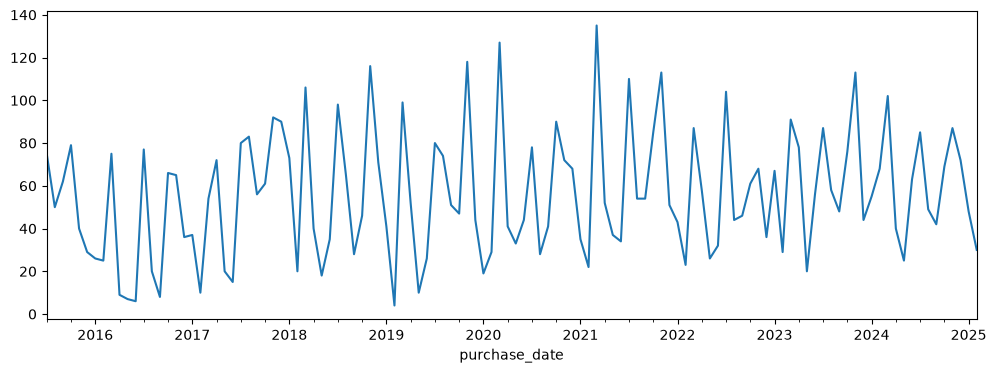

In [86]:
# Nº compras por mês
train.set_index('purchase_date').resample('ME').size().plot(figsize=(12, 4))

In [87]:
# x% das compras de cada mês tiveram recompra em 90 dias
for parte in [train['purchase_date'].dt.month]:
    print(train.groupby(parte)['repeat_purchase_90d'].mean(), "\n")

purchase_date
1.000000    0.689189
2.000000    0.619231
3.000000    0.438356
4.000000    0.511312
5.000000    0.724490
6.000000    0.604502
7.000000    0.488558
8.000000    0.609524
9.000000    0.692661
10.000000   0.636765
11.000000   0.468326
12.000000   0.587800
Name: repeat_purchase_90d, dtype: float64 



In [88]:
# taxa global
train['repeat_purchase_90d'].mean()

np.float64(0.559228650137741)

In [101]:
#tempo entre compras do mesmo cliente
train = train.sort_values(["customer_id", "purchase_date"])
train["dias_desde_ultima"] = train.groupby("customer_id")["purchase_date"].diff().dt.days

recompra_menos90 = train["dias_desde_ultima"].sort_values().loc[train["dias_desde_ultima"]<=90]
recompra_menos90

ID
10004917    1.000000
10004591    1.000000
10003795    1.000000
10006641    1.000000
10003063    1.000000
              ...   
10005243   90.000000
10001607   90.000000
10005853   90.000000
10003965   90.000000
10007171   90.000000
Name: dias_desde_ultima, Length: 3565, dtype: float64

In [116]:
train['repeat_purchase_90d'].value_counts()

repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64

<Axes: xlabel='ID', ylabel='count'>

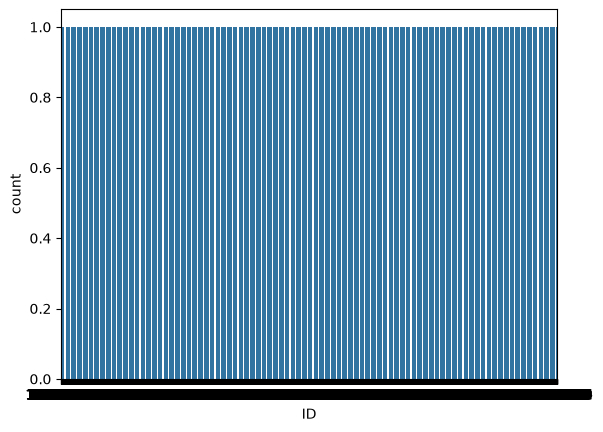

In [118]:
sns.countplot(data = train['repeat_purchase_90d'])

<Axes: >

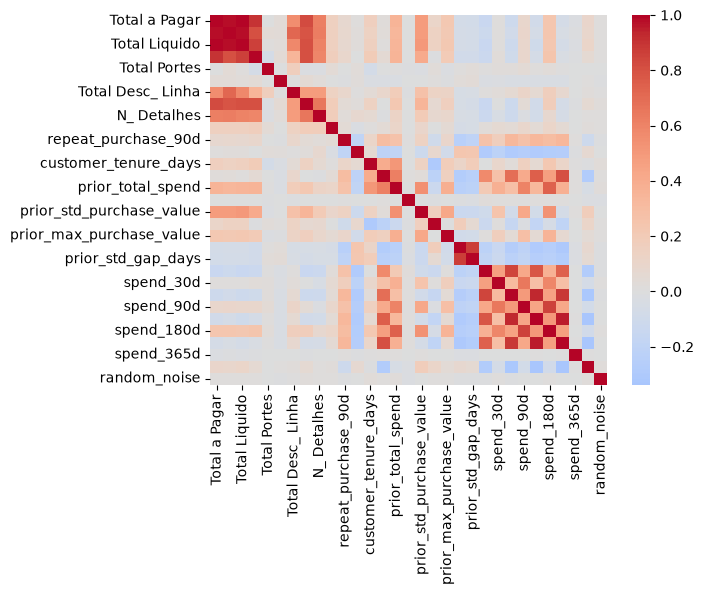

In [120]:
sns.heatmap(train[num_cols].corr(), cmap='coolwarm', center=0)

In [122]:
train[num_cols].corr()['repeat_purchase_90d'].sort_values()

prior_mean_gap_days              -0.238018
prior_std_gap_days               -0.204501
days_since_previous_purchase     -0.195541
customer_id                      -0.112005
prior_min_purchase_value         -0.098950
random_noise                     -0.011988
Total Desc_ Global               -0.011734
Total Portes                     -0.000738
prior_mean_purchase_value         0.004527
spend_365d                        0.010610
N_ Detalhes                       0.023393
Custo                             0.048374
invoice_count_current_purchase    0.049085
Total Liquido                     0.072800
Total a Pagar                     0.077731
Total Bruto                       0.082400
Total Desc_ Linha                 0.092179
Total Imp_                        0.093422
prior_max_purchase_value          0.099914
customer_tenure_days              0.106338
prior_std_purchase_value          0.134024
spend_30d                         0.165181
prior_total_spend                 0.261934
purchase_co